[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/toolkit/sklearn-models.ipynb)

# scikit-learn: Model Families

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Compare the main model families in a single fair harness.</li>
<li>Explain L1 versus L2 regularisation and read C correctly.</li>
<li>Avoid the impurity-importance trap with permutation importance.</li>
<li>Choose a sensible order in which to try models.</li>
</ul>
</div>

**Prerequisites:** <a href="../sklearn-pipelines/">scikit-learn: Pipelines and ColumnTransformer</a>. **Dataset:** Credit Card Default (Taiwan, 2005). **Time:** about 45 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_credit, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.3f}".format)

## The situation

There are dozens of model classes in scikit-learn, but they fall into a handful of **families**, each with a different idea of what a good prediction looks like, different needs (scaling, encoding) and different weaknesses. This page runs the main families through one fair harness on real data, so you can see how they compare and *why*, rather than memorising a table.

Same credit-default data and split as the previous pages.

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

credit = load_credit()
y = credit["default payment next month"]
X = credit.drop(columns=["ID", "default payment next month"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

status = [c for c in X.columns if c.startswith("PAY_") and not c.startswith("PAY_AMT")]
categorical = ["SEX", "EDUCATION", "MARRIAGE"] + status
numeric = [c for c in X.columns if c not in categorical]
for_linear = lambda: ColumnTransformer([("cats", OneHotEncoder(handle_unknown="ignore", min_frequency=50), categorical), ("nums", StandardScaler(), numeric)])
for_distance = lambda: ColumnTransformer([("cats", OneHotEncoder(handle_unknown="ignore", min_frequency=50), categorical), ("nums", StandardScaler(), numeric)])
print(f"{len(X_train):,} training rows, {len(X_test):,} test rows, default rate {y.mean():.1%}")

22,500 training rows, 7,500 test rows, default rate 22.1%


## The families at a glance

| Family | Idea | Needs scaling? | Strong when | Weak when |
|---|---|---|---|---|
| **Linear / logistic** | a weighted sum of the inputs | helpful | many features, need an explainable baseline | relationships are non-linear |
| **k-nearest neighbours** | predict like the closest examples | **yes** | few features, local patterns | many features, large data (slow), noise |
| **Support vector machine** | the widest-margin boundary | **yes** | medium data, clear margins | large data (slow); no direct probabilities |
| **Naive Bayes** | multiply per-feature likelihoods | no | tiny data, text; very fast | features are strongly dependent |
| **Decision tree** | a sequence of yes/no questions | no | needs readable rules | **overfits** unless limited |
| **Random forest** | average many de-correlated trees | no | tabular data, little tuning | memory/speed on huge data |
| **Gradient boosting** | trees built one after another, each fixing the last | no | the usual top performer on tabular data | needs tuning; can overfit noise |

## A fair harness

One function trains each model on the training rows, reports cross-validated AUC (on training data only), the AUC on the test set, and the time. Putting every model through the same function removes the chance of accidentally giving one an advantage.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def evaluate(name, model, train_rows=None):
    Xt = X_train if train_rows is None else X_train.sample(train_rows, random_state=0)
    yt = y_train.loc[Xt.index]
    t0 = time.perf_counter()
    model.fit(Xt, yt)
    seconds = time.perf_counter() - t0
    scores = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test)
    return {"model": name, "test AUC": roc_auc_score(y_test, scores), "test avg precision": average_precision_score(y_test, scores), "fit seconds": seconds,
            "trained on": f"{len(Xt):,} rows"}

candidates = [
    ("logistic regression",         make_pipeline(for_linear(), LogisticRegression(max_iter=3000)), None),
    ("naive Bayes (Gaussian)",      GaussianNB(), None),
    ("k-nearest neighbours (k=25)", make_pipeline(for_distance(), KNeighborsClassifier(25)), None),
    ("SVM, RBF kernel",             make_pipeline(for_distance(), SVC(random_state=0)), 8000),
    ("decision tree (unlimited)",   DecisionTreeClassifier(random_state=0), None),
    ("decision tree (depth 4)",     DecisionTreeClassifier(max_depth=4, random_state=0), None),
    ("random forest",               RandomForestClassifier(300, min_samples_leaf=5, n_jobs=-1, random_state=0), None),
    ("gradient boosting",           HistGradientBoostingClassifier(random_state=0), None),
]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    comparison = pd.DataFrame([evaluate(n, m, r) for n, m, r in candidates]).set_index("model").sort_values("test AUC", ascending=False)
comparison.assign(**{"test AUC": comparison["test AUC"].map("{:.3f}".format), "test avg precision": comparison["test avg precision"].map("{:.3f}".format), "fit seconds": comparison["fit seconds"].map("{:.1f}".format)})

,test AUC,test avg precision,fit seconds,trained on
model,,,,
gradient boosting,0.774,0.552,0.6,"22,500 rows"
random forest,0.774,0.556,2.0,"22,500 rows"
logistic regression,0.759,0.540,0.1,"22,500 rows"
decision tree (depth 4),0.734,0.493,0.1,"22,500 rows"
k-nearest neighbours (k=25),0.730,0.488,0.0,"22,500 rows"
"SVM, RBF kernel",0.727,0.514,1.2,"8,000 rows"
naive Bayes (Gaussian),0.642,0.402,0.0,"22,500 rows"
decision tree (unlimited),0.609,0.286,0.3,"22,500 rows"


**Reading the table.**

- **Gradient boosting and the random forest tie at the top** (about 0.774; a gap of a few thousandths between them on one split is noise). The regularised logistic regression is close behind (0.759) and fits in a fraction of the time, which is why it is the sensible first model.
- **A depth-limited tree (0.734) beats the unlimited tree (0.609) by a huge margin.** The unlimited tree memorises the training rows, the overfitting lesson from the lifecycle chapter in miniature.
- **k-NN and the SVM sit in the middle.** Note the SVM was trained on only 8,000 rows because its cost grows quickly with the number of rows, so its number is not strictly comparable. k-NN shows a fit time near zero because it does not *train*: it stores the data and pays at prediction time.
- **Naive Bayes is worst** (0.642). It assumes the features are independent given the outcome, and here they plainly are not: six monthly bills and six repayment statuses are strongly related to one another.

## Regularisation: L2 shrinks, L1 selects

Linear models can be **regularised**: a penalty on the size of the coefficients. The two common penalties behave differently. **L2 (ridge)** shrinks all coefficients smoothly toward zero. **L1 (lasso)** can push some to *exactly* zero, which is automatic feature selection. In scikit-learn, `C` is the *inverse* of the strength (small `C` = strong penalty). Watch the 14 numeric coefficients as the penalty weakens:

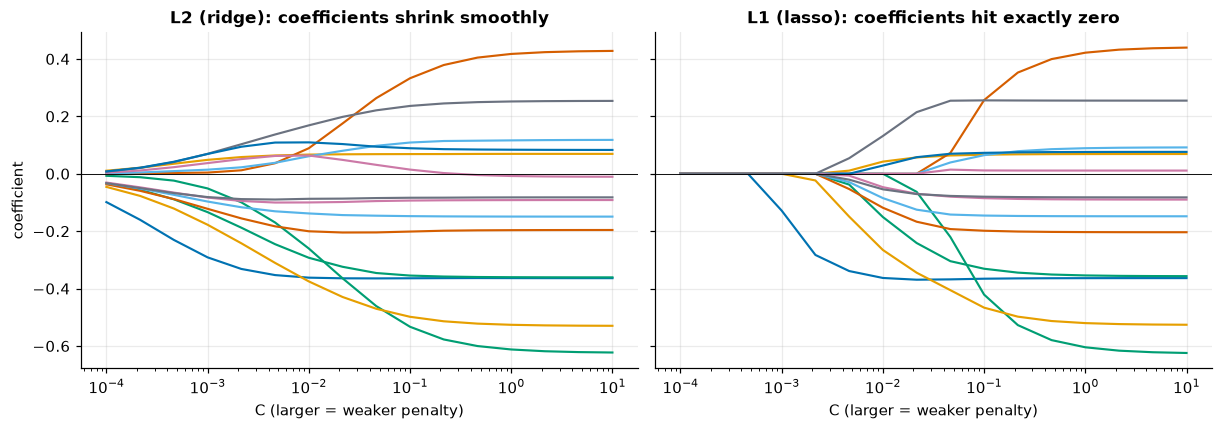

non-zero L1 coefficients (of 14) as C grows: {'C=0.0001': 0, 'C=0.001': 1, 'C=0.01': 10, 'C=0.1': 14, 'C=1': 14, 'C=10': 14}


In [4]:
Z_train = StandardScaler().fit_transform(X_train[numeric])
Cs = np.logspace(-4, 1, 16)
l2_coefs, l1_coefs = [], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for C in Cs:
        l2_coefs.append(LogisticRegression(C=C, max_iter=2000).fit(Z_train, y_train).coef_[0])
        l1_coefs.append(LogisticRegression(C=C, l1_ratio=1, solver="saga", max_iter=2000).fit(Z_train, y_train).coef_[0])
l2_coefs, l1_coefs = np.array(l2_coefs), np.array(l1_coefs)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, constrained_layout=True)
for ax, coefs, title in [(axes[0], l2_coefs, "L2 (ridge): coefficients shrink smoothly"), (axes[1], l1_coefs, "L1 (lasso): coefficients hit exactly zero")]:
    ax.plot(Cs, coefs, lw=1.4); ax.set_xscale("log"); ax.axhline(0, color="black", lw=0.6)
    ax.set(title=title, xlabel="C (larger = weaker penalty)"); 
axes[0].set_ylabel("coefficient")
plt.show()
nonzero = (l1_coefs != 0).sum(axis=1)
print("non-zero L1 coefficients (of 14) as C grows:", {f"C={c:.4g}": int(n) for c, n in zip(Cs[::3], nonzero[::3])})

**Reading the plot.** On the far left (strong penalty) every coefficient is essentially zero. As the penalty weakens, the ridge coefficients on the left grow smoothly and together. The lasso coefficients on the right start at **exactly zero** and switch on one at a time, in order of usefulness: at `C = 0.001` only one feature survives, at `C = 0.01` ten of the fourteen, and by `C = 0.1` all fourteen are in. The order in which features enter is itself informative, since the first to appear is the most useful on its own. Both families settle to the same unpenalised values on the right.

## A trap: impurity-based feature importance

Forests report `feature_importances_`, how much each feature reduced impurity across all splits. It is fast and tempting, and it has a known bias: it **favours features with many distinct values**, even useless ones. Test it by adding a column of pure random noise and see how it ranks, against **permutation importance** (shuffle a feature on *test* data and measure how much the score drops):

In [5]:
from sklearn.inspection import permutation_importance

noisy_train, noisy_test = X_train.copy(), X_test.copy()
rng = np.random.default_rng(0)
noisy_train["random_noise"], noisy_test["random_noise"] = rng.normal(size=len(noisy_train)), rng.normal(size=len(noisy_test))

forest = RandomForestClassifier(300, min_samples_leaf=5, n_jobs=-1, random_state=0).fit(noisy_train, y_train)
impurity = pd.Series(forest.feature_importances_, index=noisy_train.columns)
perm = permutation_importance(forest, noisy_test, y_test, scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=-1)
permutation = pd.Series(perm.importances_mean, index=noisy_train.columns)

ranks = pd.DataFrame({"impurity rank": impurity.rank(ascending=False).astype(int), "permutation rank": permutation.rank(ascending=False).astype(int),
                      "impurity importance": impurity, "permutation (AUC drop)": permutation})
print(f"the pure-noise column is ranked #{ranks.loc['random_noise', 'impurity rank']} of {len(ranks)} by impurity importance and #{ranks.loc['random_noise', 'permutation rank']} by permutation importance")
ranks.sort_values("permutation rank").head(6).round(4)

the pure-noise column is ranked #3 of 24 by impurity importance and #16 by permutation importance


,impurity rank,permutation rank,impurity importance,permutation (AUC drop)
PAY_0,1,1,0.147,0.070
LIMIT_BAL,7,2,0.045,0.019
PAY_2,2,3,0.061,0.013
PAY_AMT1,4,4,0.048,0.011
BILL_AMT1,5,5,0.048,0.009
PAY_3,6,6,0.047,0.007


**Reading the result.** The built-in importance ranks the **pure random column third out of 24**, above most real features, while permutation importance puts it sixteenth, correctly near zero. The reason: a random continuous column has thousands of distinct values, giving the trees endless opportunities to find a split that happens to look good on the training data. Permutation importance asks the question you actually care about (does shuffling this feature hurt predictions on *unseen* data?) and is not fooled. It also reorders some real features (`LIMIT_BAL` is seventh by impurity but second by permutation). Both agree that `PAY_0`, last month's repayment status, matters most by a wide margin.

## Which model should I try?

A practical order for tabular data:

1. **A baseline** (`DummyClassifier`) to know what "nothing" scores.
2. **Logistic / linear regression** in a pipeline: fast, explainable, and often surprisingly competitive.
3. **Gradient boosting** (`HistGradientBoosting`): the usual best performer; try it next.
4. A **random forest** as a robust cross-check that needs little tuning.
5. Only then specialised models (SVM, k-NN) if the data's shape suggests them.

Always compare with the **same split and metric**, report intervals or cross-validation spread, and prefer the simplest model that is within noise of the best.

## Check yourself

<details class="question">
<summary>1. Which of these models need feature scaling: k-NN, random forest, logistic regression, gradient boosting, SVM?</summary>

k-NN and SVM need it (they depend on distances/dot products between points), and logistic regression benefits from it (convergence, comparable coefficients, essential with regularisation). Random forests and gradient boosting do not, since trees only use the order of each feature's values.

</details>

<details class="question">
<summary>2. In scikit-learn's logistic regression, you want <em>stronger</em> regularisation. Do you raise or lower <code>C</code>?</summary>

**Lower** it. `C` is the inverse of the regularisation strength, so a small `C` means a strong penalty and coefficients shrunk toward zero. This is the opposite of ridge regression's `alpha`, which is the penalty strength itself, a classic source of confusion.

</details>

<details class="question">
<summary>3. Why shuffle a feature on the <em>test</em> set (permutation importance) rather than rely on the forest's built-in importances?</summary>

Permutation importance measures how much the model's *performance on unseen data* actually depends on a feature, so a useless feature scores near zero. The built-in impurity importance measures how often a feature was used to split the *training* data, which rewards features with many distinct values (even random noise) because they offer many chances to split.

</details>

## Exercises

<details class="question">
<summary>Which model in the comparison table takes longest to fit, and which is fastest? Is the slowest the best?</summary>

```python
print(comparison["fit seconds"].sort_values().round(2))
```

The random forest is slowest (about 2 seconds with 300 trees), gradient boosting under a second, and naive Bayes, a single tree and k-NN are nearly instant to *fit* (k-NN only stores the data). The best AUC is a tie between the two ensembles, while the logistic regression gets within about 0.015 of it in a tenth of the time. Speed and accuracy are different axes, so look at both.

</details>

<details class="question">
<summary>Fit a gradient-boosting model with <code>early_stopping=True</code> and read <code>n_iter_</code>. How many boosting rounds did it actually use out of the default 100?</summary>

```python
gb = HistGradientBoostingClassifier(early_stopping=True, random_state=0).fit(X_train, y_train)
print(gb.n_iter_)
```

Early stopping holds back a slice of the training data, monitors the score on it after each round, and stops when it stops improving. `n_iter_` is the number of rounds it kept: about 70 of the default maximum of 100 here, with a test AUC of 0.774, the same as using all 100. You get a well-sized model without having to search for the right number of trees.

</details>

## Recap

- Families differ in **idea and needs**: distance-based models need scaling; trees do not; boosting is the usual top performer on tabular data.
- Compare models in **one fair harness**: same split, metric and preprocessing; look at time as well as score.
- **L2 shrinks, L1 selects**; `C` is the *inverse* strength.
- Impurity-based importance is **biased toward high-cardinality features** (a noise column ranks high); prefer **permutation importance** on test data.
- Start with a baseline and a regularised linear model, then boosting, and prefer the simplest model that is within noise of the best.

**Next:** *Evaluation and imbalanced classes*, choosing the right metric and threshold.